In [1]:
import numpy as np
import matplotlib.pyplot as plt
from helpers.model import *
from helpers.plotting import *

In [2]:
'''
Blocks Marked with AI at the top were generated with AI.
AI was given the equations of motion and the parameters and model code
to create u, the motor controls to achieve the third performance goal.
Revision (Nov 21, 2026, AI-assisted): retuned attitude gains, replaced the fixed
1 s settle with a "hold until stopped" criterion, slowed the descent to 0.8 cm/s,
and added speed / rotor-limit / energy plots. See the markdown notes below.
'''

'\nBlocks Marked with AI at the top were generated with AI.\nAI was given the equations of motion and the parameters and model code\nto create u, the motor controls to achieve the third performance goal.\nRevision (Nov 21, 2026, AI-assisted): retuned attitude gains, replaced the fixed\n1 s settle with a "hold until stopped" criterion, slowed the descent to 0.8 cm/s,\nand added speed / rotor-limit / energy plots. See the markdown notes below.\n'

## Changes from the previous version

The previous controller failed two parts of Performance Goal 3:

1. **The stops were not stops.** After the fixed 1 s settle, the vehicle was still moving at 0.12 m/s at the end of each
   5 m leg, so the yaw and the landing began while it was still moving. The cause was poor time-scale separation: the
   position loop (poles near $-2.25 \pm 1.1i$) was only about 2x slower than the attitude loop ($-5 \pm 3.2i$), so the cascade rang.
2. **The descent peaked at 1.05 cm/s**, which is above the 1 cm/s limit.

Fixes:

* Roll/pitch attitude gains raised to $K_{p,att}=100\ \mathrm{s^{-2}}$, $K_{d,att}=20\ \mathrm{s^{-1}}$ (critically damped double pole at $-10$),
  and yaw gains to $K_{p}=25$, $K_{d}=10$ (critically damped at $-5$). The position gains are unchanged.
* Each phase runs its reference for its nominal duration, then holds until the vehicle has **actually stopped**:
  $\|\mathbf v\|<1$ mm/s, $\|\boldsymbol\omega\|<10^{-3}$ rad/s, position error $<2$ mm, heading error $<10^{-3}$ rad (minimum hold 1 s).
* Descent target speed 0.8 cm/s, reached with a 2 s cosine ease-in, which gives margin below the 1 cm/s limit.
* One shared cascade controller (`u_track`) is used for every phase instead of five copies.

In [3]:
# AI
# Shared parameters and cascade controller: position PD -> thrust & attitude refs -> attitude PD -> allocation -> rotor-speed loop

dt = 0.001        # s
z_g = 0.15        # m, touchdown CoM height

Kp_pos = np.array([6.0, 6.0, 12.0])     # s^-2
Kd_pos = np.array([4.5, 4.5, 7.0])      # s^-1
Kp_att = np.array([100.0, 100.0, 25.0]) # s^-2
Kd_att = np.array([20.0, 20.0, 10.0])   # s^-1
K_omega = 0.002                         # N m s / rad
Omega_max = 700.0                       # rad/s, checked after the run


def min_jerk(tau):
    """Rest-to-rest minimum-jerk profile s(tau) and its first two derivatives w.r.t. tau."""
    tau = np.clip(tau, 0.0, 1.0)
    return (10*tau**3 - 15*tau**4 + 6*tau**5,
            30*tau**2 - 60*tau**3 + 30*tau**4,
            60*tau - 180*tau**2 + 120*tau**3)


def u_track(r, pos_d, vel_d, acc_d, psi_d, wz_d):
    """Motor torques u (N m) that track a position / heading reference."""
    pos, vel = r[0:3], r[3:6]
    phi, theta, psi = r[6:9]
    w, Omega = r[9:12], r[12:16]

    # Outer loop: position PD + feedforward -> total thrust and roll/pitch references
    a_cmd = acc_d + Kp_pos*(pos_d - pos) + Kd_pos*(vel_d - vel)
    T_d = max(m*(a_cmd[2] + g)/(np.cos(theta)*np.cos(phi)), 0.0)
    phi_d = (a_cmd[0]*np.sin(psi) - a_cmd[1]*np.cos(psi))/g
    theta_d = (a_cmd[0]*np.cos(psi) + a_cmd[1]*np.sin(psi))/g

    # Inner loop: attitude PD -> desired body moments
    psi_err = (psi_d - psi + np.pi) % (2*np.pi) - np.pi
    att_err = np.array([phi_d - phi, theta_d - theta, psi_err])
    w_d = np.array([0.0, 0.0, wz_d])
    M_d = np.array([I1, I2, I3])*(Kp_att*att_err + Kd_att*(w_d - w))

    # Allocation -> desired rotor speeds
    c = k_T/(4.0*k_Q)
    T_i_d = np.array([T_d/4 - M_d[1]/(2*l) - c*M_d[2],
                      T_d/4 + M_d[0]/(2*l) + c*M_d[2],
                      T_d/4 + M_d[1]/(2*l) - c*M_d[2],
                      T_d/4 - M_d[0]/(2*l) + c*M_d[2]])
    Omega_d = np.sqrt(np.maximum(T_i_d, 0.0)/k_T)

    # Rotor loop: drag feedforward + speed error, limited to the 0-0.10 N m torque range
    u = k_Q*Omega**2 + K_omega*(Omega_d - Omega)
    return np.clip(u, 0.0, 0.10)


def is_stopped(r, pos_d, psi_d):
    return (np.linalg.norm(r[3:6]) < 1e-3 and np.linalg.norm(r[9:12]) < 1e-3
            and np.linalg.norm(r[0:3] - pos_d) < 2e-3 and abs(r[8] - psi_d) < 1e-3)


def run_phase(ref, r0, t_move, t_hold_min=1.0, t_max=200.0, ground=False, until_touchdown=False):
    """Forward-Euler march of one phase.

    ref(t) -> (pos_d, vel_d, acc_d, psi_d, wz_d). The phase runs the reference for t_move seconds,
    then holds until the vehicle is stopped (or, for the landing, until touchdown at z_g).
    Returns the states (n+1, 17) and the times (n+1,).
    """
    states, r, t = [r0.copy()], r0.copy(), 0.0
    while True:
        pos_d, vel_d, acc_d, psi_d, wz_d = ref(t)
        dr = state_dot(r, t, u_track(r, pos_d, vel_d, acc_d, psi_d, wz_d))
        if ground and r[2] <= z_g and dr[5] < 0:   # ground support until thrust exceeds weight
            dr[2] = dr[5] = 0.0
        r = r + dt*dr
        t += dt
        states.append(r.copy())
        if until_touchdown:
            if r[2] <= z_g:
                break
        elif t >= t_move + t_hold_min and is_stopped(r, ref(t)[0], ref(t)[3]):
            break
        if t > t_max:
            raise RuntimeError('phase did not finish within t_max')
    states = np.array(states)
    return states, np.arange(len(states))*dt

In [4]:
# AI
# Phase 1: launch from (0, 0, z_g) at rest with rotors stopped, ascend to (0, 0, 1)

r0_a = np.zeros(17)
r0_a[2] = z_g
p_hover_a = np.array([0.0, 0.0, 1.0])

ref_ascend = lambda t: (p_hover_a, np.zeros(3), np.zeros(3), 0.0, 0.0)
r_ascend, times_a = run_phase(ref_ascend, r0_a, t_move=3.0, ground=True)

In [5]:
# AI
# Phase 2: 5 m translation (0, 0, 1) -> (5, 0, 1); minimum-jerk reference over 5 s = 1 m/s average, then stop

T_leg = 5.0  # s

def leg_ref(p_start, p_end, psi):
    p_start, p_end = np.asarray(p_start, float), np.asarray(p_end, float)
    d = p_end - p_start
    def ref(t):
        s, sd, sdd = min_jerk(t/T_leg)
        return p_start + d*s, d*sd/T_leg, d*sdd/T_leg**2, psi, 0.0
    return ref

r_trans1, times_t1 = run_phase(leg_ref([0, 0, 1], [5, 0, 1], 0.0), r_ascend[-1], t_move=T_leg)

In [6]:
# AI
# Phase 3: stopped +pi/2 (left) yaw at (5, 0, 1), minimum-jerk heading reference over 3 s, then stop

T_yaw = 3.0  # s
p_yaw = np.array([5.0, 0.0, 1.0])

def ref_yaw(t):
    s, sd, _ = min_jerk(t/T_yaw)
    return p_yaw, np.zeros(3), np.zeros(3), (np.pi/2)*s, (np.pi/2)*sd/T_yaw

r_yaw, times_y = run_phase(ref_yaw, r_trans1[-1], t_move=T_yaw)

In [7]:
# AI
# Phase 4: 5 m translation (5, 0, 1) -> (5, 5, 1) along the new heading psi = +pi/2, then stop

r_trans2, times_t2 = run_phase(leg_ref([5, 0, 1], [5, 5, 1], np.pi/2), r_yaw[-1], t_move=T_leg)

In [8]:
# AI
# Phase 5: vertical landing at (5, 5) from z = 1 to z_g, target 0.8 cm/s (limit 1 cm/s)

v_desc = -0.008  # m/s
T_ramp = 2.0     # s, cosine ease-in from hover to v_desc
z_start_d = r_trans2[-1, 2]

def ref_descend(t):
    if t < T_ramp:
        vzd = 0.5*v_desc*(1.0 - np.cos(np.pi*t/T_ramp))
        zd = z_start_d + 0.5*v_desc*(t - (T_ramp/np.pi)*np.sin(np.pi*t/T_ramp))
    else:
        vzd = v_desc
        zd = z_start_d + 0.5*v_desc*T_ramp + v_desc*(t - T_ramp)
    return np.array([5.0, 5.0, zd]), np.array([0.0, 0.0, vzd]), np.zeros(3), np.pi/2, 0.0

# Flight integration ends at touchdown (z = z_g)
r_descend, times_d = run_phase(ref_descend, r_trans2[-1], t_move=0.0, until_touchdown=True)

In [9]:
# Stitch the phases into one mission timeline
phase_names = ['1 m ascension', '5 m x-translation', 'Rotation', '5 m y-translation', '1 m descension']
phase_states = [r_ascend, r_trans1, r_yaw, r_trans2, r_descend]
phase_times = [times_a, times_t1, times_y, times_t2, times_d]

offsets = np.cumsum([0.0] + [t[-1] for t in phase_times[:-1]])
phase_times_abs = [t + o for t, o in zip(phase_times, offsets)]

r_all = np.vstack([phase_states[0]] + [s[1:] for s in phase_states[1:]])
t_all = np.concatenate([phase_times_abs[0]] + [t[1:] for t in phase_times_abs[1:]])

In [10]:
# Requirement checks for Performance Goal 3
print('Phase timeline:')
for name, s, t in zip(phase_names, phase_states, phase_times_abs):
    speed_end = np.linalg.norm(s[-1, 3:6])
    print(f'  {name:18s} t = [{t[0]:7.3f}, {t[-1]:7.3f}] s   end position = {np.round(s[-1, 0:3], 4)}   '
          f'end speed = {1000*speed_end:.3f} mm/s   end psi = {s[-1, 8]:.4f} rad')

lift_idx = np.argmax(r_ascend[:, 2] > z_g + 1e-9)
print(f'\nLift-off at t = {times_a[lift_idx]:.3f} s; max altitude during ascent = {r_ascend[:, 2].max():.4f} m')

for name, s, axis in [('x-leg', r_trans1, 0), ('y-leg', r_trans2, 1)]:
    i5 = int(round(T_leg/dt))
    print(f'{name}: position after 5 s = {s[i5, axis]:.4f} m (avg {s[i5, axis] - s[0, axis]:.3f} m / 5 s); '
          f'peak speed = {np.linalg.norm(s[:, 3:6], axis=1).max():.3f} m/s; overshoot = {1000*(s[:, axis].max() - 5):.2f} mm')

print(f'Yaw: peak heading = {np.degrees(r_yaw[:, 8].max()):.2f} deg (target 90 deg)')

speed_d = np.linalg.norm(r_descend[:, 3:6], axis=1)
print(f'\nDescent: duration = {times_d[-1]:.3f} s, peak vertical speed = {100*(-r_descend[:, 5]).max():.4f} cm/s, '
      f'peak total speed = {100*speed_d.max():.4f} cm/s, touchdown speed = {100*speed_d[-1]:.4f} cm/s')
print(f'         max climb rate during descent = {100*r_descend[:, 5].max():.5f} cm/s (must be <= 0)')
print(f'         max horizontal drift = {1000*np.abs(r_descend[:, 0:2] - 5).max():.3f} mm')

print(f'\nRotor speed range: [{r_all[:, 12:16].min():.1f}, {r_all[:, 12:16].max():.1f}] rad/s (ceiling {Omega_max:.0f})')
assert r_all[:, 12:16].max() <= Omega_max and r_all[:, 12:16].min() >= 0.0
assert speed_d.max() <= 0.01, 'landing speed limit violated'

Phase timeline:
  1 m ascension      t = [  0.000,   4.001] s   end position = [0.     0.     0.9998]   end speed = 0.501 mm/s   end psi = 0.0000 rad
  5 m x-translation  t = [  4.001,  12.013] s   end position = [4.9998 0.     1.    ]   end speed = 0.685 mm/s   end psi = -0.0000 rad
  Rotation           t = [ 12.013,  17.311] s   end position = [ 5. -0.  1.]   end speed = 0.000 mm/s   end psi = 1.5711 rad
  5 m y-translation  t = [ 17.311,  25.323] s   end position = [5.     4.9998 1.    ]   end speed = 0.685 mm/s   end psi = 1.5708 rad
  1 m descension     t = [ 25.323, 132.574] s   end position = [5.   5.   0.15]   end speed = 8.000 mm/s   end psi = 1.5708 rad

Lift-off at t = 0.424 s; max altitude during ascent = 0.9998 m
x-leg: position after 5 s = 4.9732 m (avg 4.973 m / 5 s); peak speed = 1.900 m/s; overshoot = 0.10 mm
y-leg: position after 5 s = 4.9732 m (avg 4.973 m / 5 s); peak speed = 1.900 m/s; overshoot = 0.10 mm
Yaw: peak heading = 91.43 deg (target 90 deg)

Descent: dura

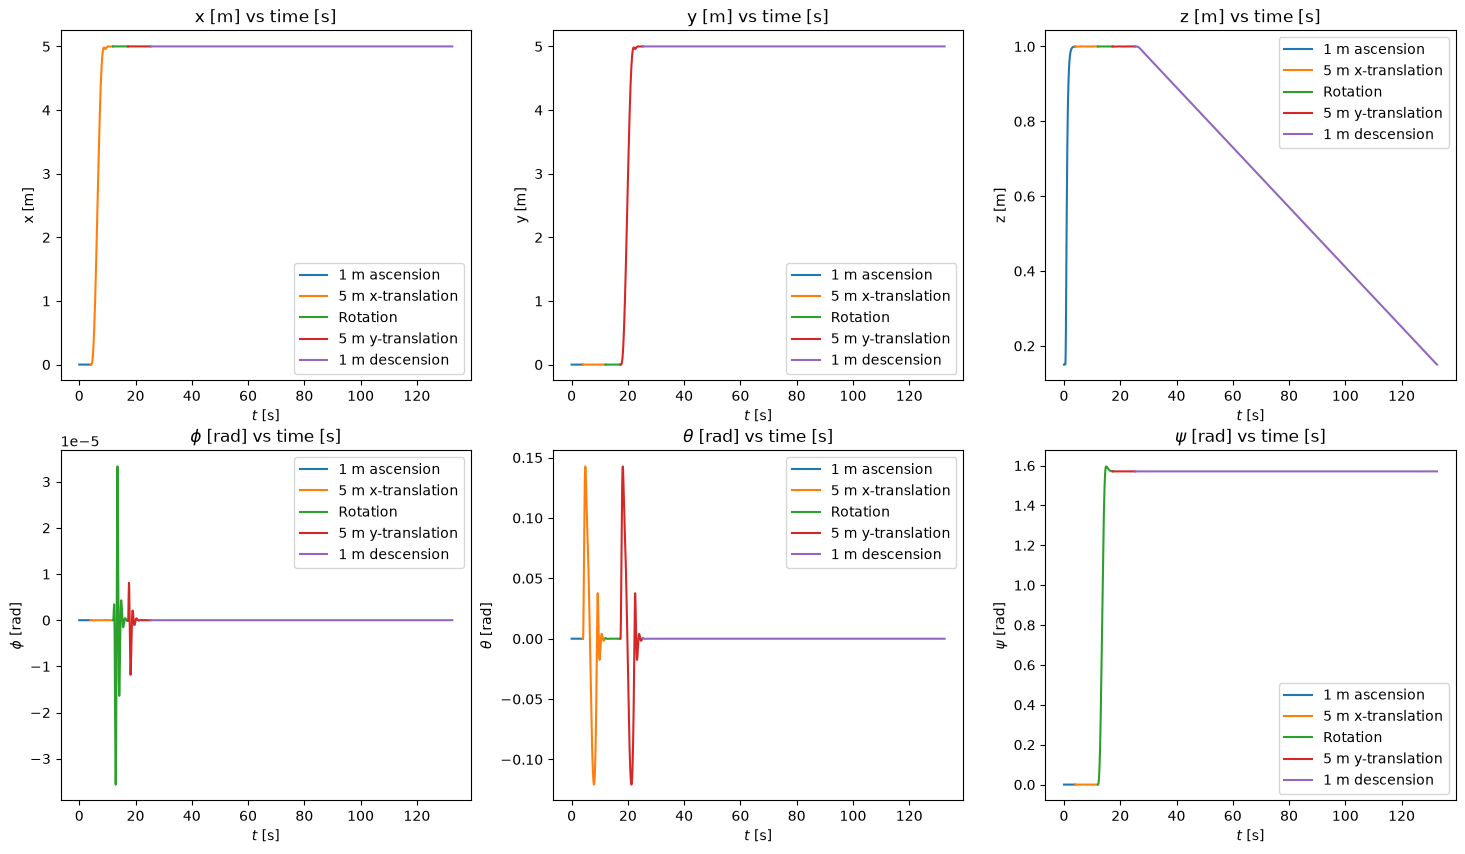

In [11]:
fig = plotDegreesOfFreedom(phase_times_abs[0], phase_states[0], phase_names[0])
for name, s, t in zip(phase_names[1:], phase_states[1:], phase_times_abs[1:]):
    plotMoreDegreesOfFreedom(fig, t, s, name)

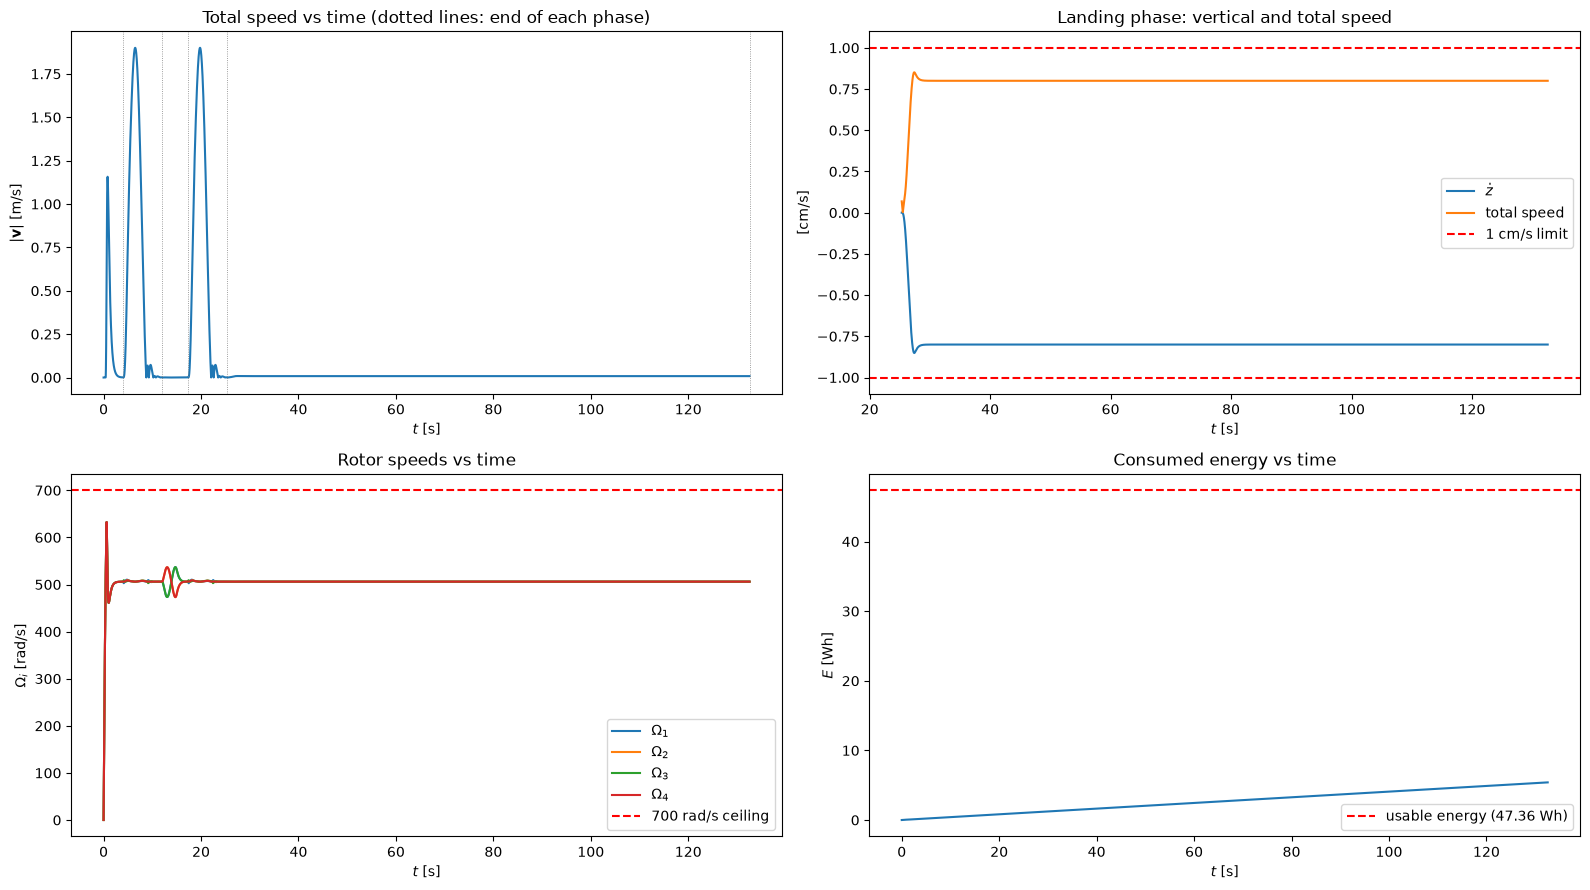

In [12]:
# Speed, descent rate, rotor speeds and energy over the mission
fig2, ax = plt.subplots(2, 2, figsize=(16, 9))

speed = np.linalg.norm(r_all[:, 3:6], axis=1)
ax[0, 0].plot(t_all, speed)
for t in phase_times_abs:
    ax[0, 0].axvline(t[-1], color='gray', lw=0.6, ls=':')
ax[0, 0].set(title='Total speed vs time (dotted lines: end of each phase)', xlabel='$t$ [s]', ylabel='$|\\mathbf{v}|$ [m/s]')

ax[0, 1].plot(times_d + phase_times_abs[4][0], 100*r_descend[:, 5], label='$\\dot z$')
ax[0, 1].plot(times_d + phase_times_abs[4][0], 100*np.linalg.norm(r_descend[:, 3:6], axis=1), label='total speed')
ax[0, 1].axhline(-1.0, color='r', ls='--', label='1 cm/s limit')
ax[0, 1].axhline(1.0, color='r', ls='--')
ax[0, 1].set(title='Landing phase: vertical and total speed', xlabel='$t$ [s]', ylabel='[cm/s]')
ax[0, 1].legend()

for i in range(4):
    ax[1, 0].plot(t_all, r_all[:, 12 + i], label=f'$\\Omega_{i+1}$')
ax[1, 0].axhline(Omega_max, color='r', ls='--', label='700 rad/s ceiling')
ax[1, 0].set(title='Rotor speeds vs time', xlabel='$t$ [s]', ylabel='$\\Omega_i$ [rad/s]')
ax[1, 0].legend()

ax[1, 1].plot(t_all, r_all[:, 16]/3600)
ax[1, 1].axhline(E_available/3600, color='r', ls='--', label='usable energy (47.36 Wh)')
ax[1, 1].set(title='Consumed energy vs time', xlabel='$t$ [s]', ylabel='$E$ [Wh]')
ax[1, 1].legend()
fig2.tight_layout()

In [13]:
E_test3 = r_descend[-1][16]
E_left_test3 = E_available - E_test3
print(f'Energy Used: {E_test3:.2f} J ({E_test3/3600:.3f} Wh, {100*E_test3/E_available:.2f}% of usable)')
print(f'Energy left: {E_left_test3:.2f} J')
print(f'Mission time to touchdown: {t_all[-1]:.3f} s')

Energy Used: 19455.52 J (5.404 Wh, 11.41% of usable)
Energy left: 151040.48 J
Mission time to touchdown: 132.574 s


In [14]:
fig.savefig("figures/PG3-DegreesOfFreedom.pdf", format="pdf", bbox_inches="tight")
fig2.savefig("figures/PG3-Speed-Rotors-Energy.pdf", format="pdf", bbox_inches="tight")